In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def polar(amp, ph):
    return amp*np.exp(np.deg2rad(ph)*1j)

In [3]:
def print_result(a):
    print(f'amp: {np.abs(a):.2f}, ph: {np.rad2deg(np.angle(a))%360:.2f}')


In [4]:
def get_l(mode, a, b, c):
    # функция переводит расстояния между точками в расстояние от точки А в зависимости от выбранной схемы балансировки
    # Входные параметры:
    # select - str - значение выбранной схемы
    # a,b,c - расстояния между плоскостями балансировки
    # a: A-1
    # b: 1-2
    # c: 2-B
    match mode:

        case 'mo':
            l_1 = a
            l_2 = a + b
            l = a + b + c

        case 'pk':
            l_1 = a
            l_2 = a + b
            l = a + b - c

        case 'lk':
            l_1 = -a
            l_2 = b - a
            l = b + c - a

        case 'mopk':
            l_1 = a
            l_2 = a + b
            l = a + b - c

        case 'lkmo':
            l_1 = -a
            l_2 = b - a
            l = b + c - a
           

        case 'dk':
            l_1 = -a
            l_2 = b - a
            l = b - c - a
    return l_1, l_2, l

# Калибровка

## Входные данные

In [5]:
R_1 = polar(62, -20)
m_1 = 2.667

R_2 = polar(62, 170)
m_2 = 2.667

a = 75
b = 195
c = 265

n = 1506

x_A = polar(6.6, 40)
x_B = polar(7, 50)

h = 5
q = 1

## Вычисления

In [6]:
w = 2 * np.pi * n / 60

z_A = 0
z_1, z_2, z_B = get_l('mo', a, b, c)

T_1 = m_1*R_1
T_2 = m_2*R_2

D_1 = T_1*w**2*1e-6
D_2 = T_2*w**2*1e-6

D_A = (D_1*(z_1-z_B)+D_2*(z_2-z_B))/(z_A-z_B)
D_B = (D_1*(z_1-z_A)+D_2*(z_2-z_A))/(z_B-z_A)

k_A = D_A/x_A
k_B = D_B/x_B

## Результат

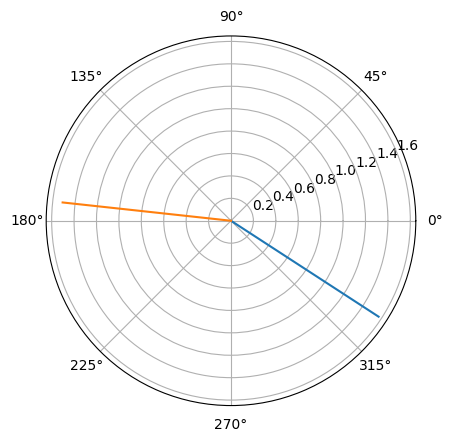

In [7]:

plt.polar([0, np.angle(D_A)], [0, np.abs(D_A)])
plt.polar([0, np.angle(D_B)], [0, np.abs(D_B)])

In [8]:
print_result(k_A)
print_result(k_B)

amp: 0.24, ph: 286.98
amp: 0.22, ph: 123.80


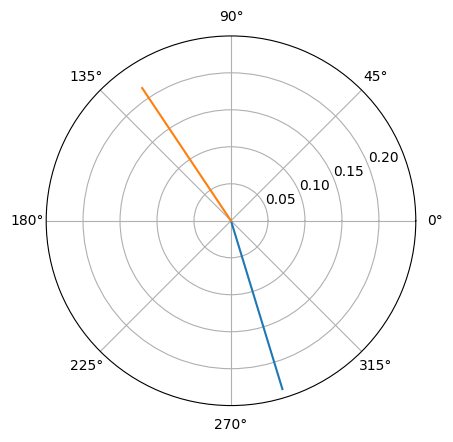

In [9]:
plt.polar([0, np.angle(k_A)], [0, np.abs(k_A)])
plt.polar([0, np.angle(k_B)], [0, np.abs(k_B)])

# Балансировка

In [10]:
D_A=k_A*x_A
D_B=k_B*x_B

D_1=(D_A*(z_A-z_2)+D_B*(z_B-z_2))/(z_1-z_2)
D_2=(D_A*(z_A-z_1)+D_B*(z_B-z_1))/(z_2-z_1)

r_1=np.abs(R_1)
r_2=np.abs(R_2)

M_1=D_1 * 1e+6 / (w ** 2 * r_1)
M_2=D_2 * 1e+6 / (w ** 2 * r_2)


## Результат

In [11]:
print_result(M_1)
print_result(M_2)

amp: 2.67, ph: 340.00
amp: 2.67, ph: 170.00


# Проверка

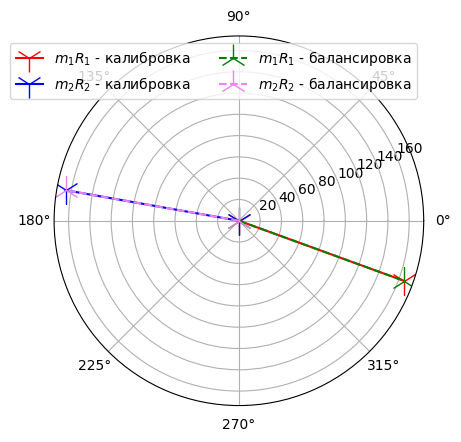

In [12]:
plt.polar([0, np.angle(r_1*M_1)], [0, np.abs(r_1*M_1)],color='red',marker='1',markersize=20,label='$m_1R_1$ - калибровка')
plt.polar([0, np.angle(r_2*M_2)], [0, np.abs(r_2*M_2)],color='blue',marker='1',markersize=20,label='$m_2R_2$ - калибровка')

plt.polar([0, np.angle(m_1*R_1)], [0, np.abs(m_1*R_1)],color='green',ls='--',marker='2',markersize=20,label='$m_1R_1$ - балансировка')
plt.polar([0, np.angle( m_2*R_2)], [0,np.abs( m_2*R_2)],color='violet',ls='--',marker='2',markersize=20,label='$m_2R_2$ - балансировка')

plt.legend(ncol=2)

In [13]:
print_result(r_1*M_1)
print_result(r_2*M_2)
print_result(m_1*R_1)
print_result(m_2*R_2)


amp: 165.35, ph: 340.00
amp: 165.35, ph: 170.00
amp: 165.35, ph: 340.00
amp: 165.35, ph: 170.00
